In [1]:
import pandas as pd
from pathlib import Path
import glob
import json

import matplotlib.pyplot as plt

In [2]:
ALL_TEST_PHASES = ["simulation_full_year_potsdam", "simulation_full_year_garmisch", "simulation_full_year_mannheim", "simulation_full_year_hamburg", "simulation_full_year_essen"]
TEST_PHASE = "simulation_full_year_potsdam"

SOURCES_TO_COMPARE = ["all_closed", "hard_coded_control", "drl_ambient_adjusted", "drl_ambient_adjusted_measured", "drl_ambient_adjusted_weather_like_measured"]

name_to_short_label = {
    "all_closed": "Alle geschlossen",
    "random_control": "Zufallsbasiert",
    "hard_coded_control": "Regelbasiert",
    "drl_baseline": "Sim-comfort\n(stg. weather)",
    "drl_ambient_adjusted": "Sim-causality\n(stg. weather)",
    "drl_ambient_adjusted_measured": "Mess-causality\n(mess. weather)",
    "drl_ambient_adjusted_weather_like_measured": "Sim-causality\n(mess. weather)",
    "drl_ambient_adjusted": "Sim-causality\n(stg. weather)",

    "simulation_full_year_potsdam": "Potsdam",
    "simulation_full_year_garmisch": "Garmisch-Partenkirchen",
    "simulation_full_year_mannheim": "Mannheim",
    "simulation_full_year_hamburg": "Hamburg",
    "simulation_full_year_essen": "Essen"
}

CONTROL_ACTIONS = {
    "all_closed": 0, # for winter night
    "all_open": 2, # for summer night
    "inside_open": 1, # for winter day (with radiation)
    "outside_open": -1 # for summer day
}

In [3]:
# def din_comfort_band(ambient_temp):
#     if ambient_temp < 16:
#         return (20, 22, 24)
#     elif ambient_temp < 32:
#         return (16 + 0.25 * ambient_temp, 18 + 0.25 * ambient_temp, 20 + 0.25 * ambient_temp)
#     else:
#         return (24, 26, 28)

def din_comfort_band(ambient_temp):
    return (20, 21, 22)

# Vektorisierte Variante (arbeitet auf ganzen Spalten statt Zeile für Zeile -> deutlich schneller)
# def din_comfort_band_vec(ambient_temp):
#     ambient_temp = np.asarray(ambient_temp, dtype=float)
#     lower = np.where(ambient_temp < 16, 20.0, np.where(ambient_temp < 32, 16 + 0.25 * ambient_temp, 24.0))
#     return lower, lower + 2, lower + 4

def din_comfort_band_vec(ambient_temp):
    ambient_temp = np.asarray(ambient_temp, dtype=float)
    lower = np.full_like(ambient_temp, 20.0)
    return lower, lower + 1, lower + 2

def inside_comfort_band(ambient_temp, operative_temp):
    lower, mid, upper = din_comfort_band(ambient_temp)
    if lower <= operative_temp <= upper:
        return True
    else:
        return False

def overheating_hours(ambient_temp, operative_temp):
    lower, mid, upper = din_comfort_band(ambient_temp)
    if operative_temp > upper:
        return operative_temp - upper
    else:
        return 0

def undercooling_hours(ambient_temp, operative_temp):
    lower, mid, upper = din_comfort_band(ambient_temp)
    if operative_temp < lower:
        return lower - operative_temp
    else:
        return 0

def median_run_data(df, metric="inside_comfort", verbose=True):
    """Nur den Median-Lauf je Strategie behalten (Ranking nach Summe von `metric`, Standard: Komfortstunden).
    Bei gerader Seed-Anzahl der untere der beiden mittleren Läufe; Strategien ohne Seeds bleiben unverändert.
    `df` sollte nur einen Standort (test_phase) enthalten."""
    runs = (
        df.groupby(["source", "seed"], dropna=False)[metric].sum()
        .reset_index().sort_values(["source", metric])
    )
    grouped = runs.groupby("source")
    median_runs = runs[grouped.cumcount() == (grouped[metric].transform("size") - 1) // 2]
    if verbose:
        print("Median runs:", ", ".join(f"{s} (seed {sd})" for s, sd in zip(median_runs["source"], median_runs["seed"])))
    run_key = df["source"] + "|" + df["seed"].astype("string").fillna("-")
    median_keys = set(median_runs["source"] + "|" + median_runs["seed"].astype("string").fillna("-"))
    return df[run_key.isin(median_keys)]

In [4]:
import re
import numpy as np

SEED_PATTERN = re.compile(r"^(?P<source>.+?)_seed_?(?P<seed>\d+)$")

def split_source_seed(dir_name):
    """'drl_ambient_adjusted_seed1' / '..._seed_1' -> ('drl_ambient_adjusted', 1); ohne Seed -> (name, None)."""
    match = SEED_PATTERN.match(dir_name)
    if match:
        return match["source"], int(match["seed"])
    return dir_name, None

def flatten_record(record):
    # Records sind nur eine Ebene verschachtelt ({"misc": {...}, "state": {...}, "control": 1, ...}).
    # Direktes Flachklopfen ist viel schneller als pd.json_normalize; Spaltennamen = letzter Schlüssel.
    flat = {}
    for key, value in record.items():
        if isinstance(value, dict):
            flat.update(value)
        else:
            flat[key] = value
    return flat

def load_source(source_path):
    rows = []
    for file_path in source_path.glob("*.jsonl"):
        with open(file_path, encoding="utf-8") as file:
            rows.extend(flatten_record(json.loads(line)) for line in file if line.strip())
    return pd.DataFrame(rows) if rows else None

phase_frames = []
start_date = pd.Timestamp("2024-01-01")

for test_phase in ALL_TEST_PHASES:
    results_path = Path(fr"C:\Users\lkclu\Documents\GitHub\DTFS\results\control\{test_phase}")

    frames = []
    for source_path in results_path.iterdir():
        if not source_path.is_dir():
            continue
        source, seed = split_source_seed(source_path.name)
        if source not in SOURCES_TO_COMPARE:
            continue  # nicht benötigte Quellen gar nicht erst einlesen
        frame = load_source(source_path)
        if frame is None:
            continue
        frame["source"] = source
        frame["seed"] = seed
        frames.append(frame)

    if not frames:
        raise FileNotFoundError(f"No JSONL result files found in {results_path}")

    phase_data = pd.concat(frames, ignore_index=True)
    phase_data["seed"] = phase_data["seed"].astype("Int64")
    phase_data["datetime"] = start_date + pd.to_timedelta(phase_data["current_time"], unit="h")

    t_amb = phase_data["dry_bulb_temperature"].to_numpy(dtype=float)
    t_op = phase_data["operative_temperature"].to_numpy(dtype=float)
    t_low, t_mid, t_high = din_comfort_band_vec(t_amb)
    phase_data["t_low"], phase_data["t_mid"], phase_data["t_high"] = t_low, t_mid, t_high
    phase_data["inside_comfort"] = (t_op >= t_low) & (t_op <= t_high)
    phase_data["overheating"] = np.clip(t_op - t_high, 0, None)
    phase_data["undercooling"] = np.clip(t_low - t_op, 0, None)
    phase_data["test_phase"] = test_phase

    phase_frames.append(phase_data)

all_data = pd.concat(phase_frames, ignore_index=True)
all_data.groupby(["test_phase", "source"], dropna=False)["seed"].unique()

test_phase                     source                                    
simulation_full_year_essen     all_closed                                             [<NA>]
                               drl_ambient_adjusted                          [1, 2, 3, 4, 5]
                               drl_ambient_adjusted_measured                          [<NA>]
                               drl_ambient_adjusted_weather_like_measured    [1, 2, 3, 4, 5]
                               hard_coded_control                                     [<NA>]
simulation_full_year_garmisch  all_closed                                             [<NA>]
                               drl_ambient_adjusted                          [1, 2, 3, 4, 5]
                               drl_ambient_adjusted_measured                          [<NA>]
                               drl_ambient_adjusted_weather_like_measured    [1, 2, 3, 4, 5]
                               hard_coded_control                                     [<N

In [5]:
all_data.head()

,hour_of_day,current_time,dry_bulb_temperature,total_horizontal_radiation,operative_temperature,control,source,seed,datetime,t_low,t_mid,t_high,inside_comfort,overheating,undercooling,test_phase
0,0.166667,0.166667,-0.95,0.0,20.613411,0,all_closed,<NA>,2024-01-01 00:10:00.000000001,20.0,21.0,22.0,True,0.0,0.000000,simulation_full_year_potsdam
1,0.333333,0.333333,-1.25,0.0,19.894366,0,all_closed,<NA>,2024-01-01 00:19:59.999999998,20.0,21.0,22.0,False,0.0,0.105634,simulation_full_year_potsdam
2,0.500000,0.500000,-1.55,0.0,19.274803,0,all_closed,<NA>,2024-01-01 00:30:00.000000000,20.0,21.0,22.0,False,0.0,0.725197,simulation_full_year_potsdam
3,0.666667,0.666667,-1.85,0.0,18.738566,0,all_closed,<NA>,2024-01-01 00:40:00.000000001,20.0,21.0,22.0,False,0.0,1.261434,simulation_full_year_potsdam
4,0.833333,0.833333,-2.15,0.0,18.272105,0,all_closed,<NA>,2024-01-01 00:49:59.999999998,20.0,21.0,22.0,False,0.0,1.727895,simulation_full_year_potsdam


In [6]:
all_data["test_phase"].unique()

array(['simulation_full_year_potsdam', 'simulation_full_year_garmisch',
       'simulation_full_year_mannheim', 'simulation_full_year_hamburg',
       'simulation_full_year_essen'], dtype=object)

In [7]:
data = all_data[all_data["test_phase"] == TEST_PHASE]

In [8]:
data.head()

,hour_of_day,current_time,dry_bulb_temperature,total_horizontal_radiation,operative_temperature,control,source,seed,datetime,t_low,t_mid,t_high,inside_comfort,overheating,undercooling,test_phase
0,0.166667,0.166667,-0.95,0.0,20.613411,0,all_closed,<NA>,2024-01-01 00:10:00.000000001,20.0,21.0,22.0,True,0.0,0.000000,simulation_full_year_potsdam
1,0.333333,0.333333,-1.25,0.0,19.894366,0,all_closed,<NA>,2024-01-01 00:19:59.999999998,20.0,21.0,22.0,False,0.0,0.105634,simulation_full_year_potsdam
2,0.500000,0.500000,-1.55,0.0,19.274803,0,all_closed,<NA>,2024-01-01 00:30:00.000000000,20.0,21.0,22.0,False,0.0,0.725197,simulation_full_year_potsdam
3,0.666667,0.666667,-1.85,0.0,18.738566,0,all_closed,<NA>,2024-01-01 00:40:00.000000001,20.0,21.0,22.0,False,0.0,1.261434,simulation_full_year_potsdam
4,0.833333,0.833333,-2.15,0.0,18.272105,0,all_closed,<NA>,2024-01-01 00:49:59.999999998,20.0,21.0,22.0,False,0.0,1.727895,simulation_full_year_potsdam


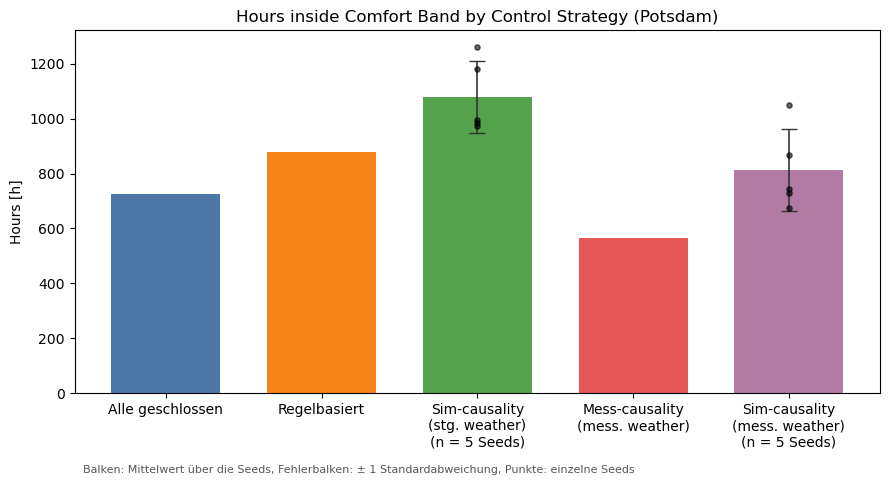

,mean,std,count
source,,,
Alle geschlossen,725.5,NaN,1
Regelbasiert,876.8,NaN,1
Sim-causality (stg. weather),1079.2,132.0,5
Mess-causality (mess. weather),565.7,NaN,1
Sim-causality (mess. weather),812.4,149.0,5


In [9]:
# Komfortstunden je (source, seed); Quellen ohne Seed haben seed = <NA>
comfort_per_seed = (
    data.groupby(["source", "seed"], dropna=False)["inside_comfort"].sum() / 6
).rename("Comfort hours").reset_index()

# Mittelwert und Standardabweichung über die Seeds (kein Fehlerbalken bei nur einem Lauf)
summary = (
    comfort_per_seed.groupby("source")["Comfort hours"]
    .agg(["mean", "std", "count"])
    .reindex(SOURCES_TO_COMPARE).dropna(subset=["mean"])
)

colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#B279A2", "#72B7B2", "#FF9DA6"]
x = np.arange(len(summary))

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x, summary["mean"], width=0.7, color=colors[:len(summary)],
       yerr=summary["std"].where(summary["count"] > 1), capsize=6, error_kw=dict(ecolor="#333333", lw=1.2))

# einzelne Seeds als Punkte
for i, source in enumerate(summary.index):
    values = comfort_per_seed.loc[comfort_per_seed["source"] == source, "Comfort hours"]
    if len(values) > 1:
        ax.scatter(np.full(len(values), i), values, s=14, color="black", alpha=0.6, zorder=3)

labels = [
    name_to_short_label.get(source, source) + (f"\n(n = {int(n)} Seeds)" if n > 1 else "")
    for source, n in zip(summary.index, summary["count"])
]
ax.set_xticks(x, labels)
ax.set_ylabel("Hours [h]")
ax.set_title(f"Hours inside Comfort Band by Control Strategy ({name_to_short_label.get(TEST_PHASE, TEST_PHASE)})")
ax.text(0.01, -0.22, "Balken: Mittelwert über die Seeds, Fehlerbalken: ± 1 Standardabweichung, Punkte: einzelne Seeds",
        transform=ax.transAxes, fontsize=8, color="#555555")
plt.tight_layout()
plt.show()

summary.rename(index=lambda s: name_to_short_label.get(s, s).replace("\n", " ")).round(1)

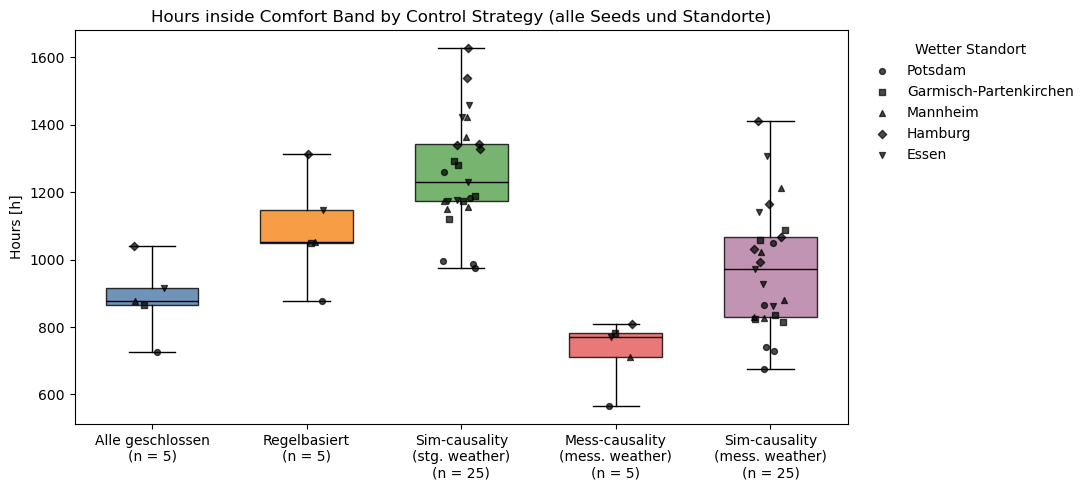

In [10]:
# one comfort-hours value per run (source, seed, test_phase)
comfort_per_run = (
    all_data.groupby(["source", "seed", "test_phase"], dropna=False)["inside_comfort"].sum() / 6  # 10-min-Schritte -> Stunden
).rename("Comfort hours").reset_index()

# keep order of SOURCES_TO_COMPARE and drop sources without data
sources = [s for s in SOURCES_TO_COMPARE if s in comfort_per_run["source"].unique()]
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#B279A2", "#72B7B2", "#FF9DA6"]

# alle Läufe (Seeds × Standorte) je Strategie
box_data = [comfort_per_run.loc[comfort_per_run["source"] == s, "Comfort hours"].values for s in sources]
labels = [f"{name_to_short_label.get(s, s)}\n(n = {len(v)})" for s, v in zip(sources, box_data)]

# plot
fig, ax = plt.subplots(figsize=(11, 5))
bp = ax.boxplot(box_data, patch_artist=True, widths=0.6, tick_labels=labels, whis=(0, 100))

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
for median in bp["medians"]:
    median.set_color("black")

# overlay the individual runs, eine Markerform je Standort (leicht horizontal verteilt)
PHASE_MARKERS = dict(zip(ALL_TEST_PHASES, ["o", "s", "^", "D", "v", "P", "X"]))
rng = np.random.default_rng(0)
for i, source in enumerate(sources, start=1):
    runs = comfort_per_run[comfort_per_run["source"] == source]
    for phase, marker in PHASE_MARKERS.items():
        values = runs.loc[runs["test_phase"] == phase, "Comfort hours"].values
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(values)), values, marker=marker,
                   color="black", s=18, alpha=0.7, zorder=3,
                   label=name_to_short_label.get(phase, phase) if i == 1 else None)
ax.legend(title="Wetter Standort", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)

ax.set_ylabel("Hours [h]")
ax.set_xlabel("")
ax.set_title("Hours inside Comfort Band by Control Strategy (alle Seeds und Standorte)")
plt.tight_layout()
plt.show()

Median runs: all_closed (seed <NA>), drl_ambient_adjusted (seed 2), drl_ambient_adjusted_measured (seed <NA>), drl_ambient_adjusted_weather_like_measured (seed 5), hard_coded_control (seed <NA>)
262770
13138


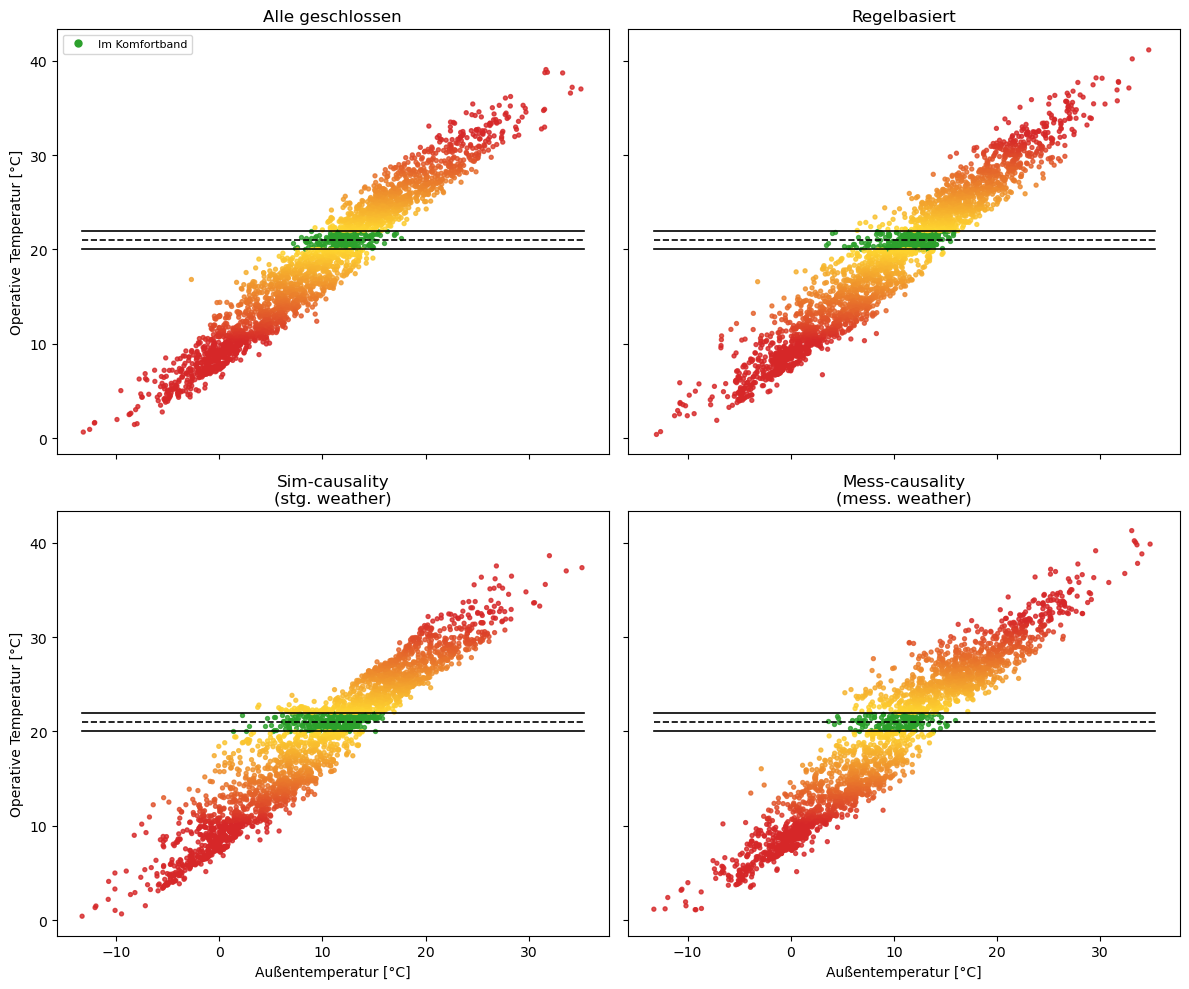

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D

# Median run je Strategie (nach Komfortstunden am gewählten Standort)
median_data = median_run_data(data)

print(len(median_data))
selected_data = median_data.sample(frac=0.05, random_state=42)
print(len(selected_data))

# Abweichung vom Komfortband in K (0 = im Band)
selected_data = selected_data.assign(
    deviation=selected_data["overheating"] + selected_data["undercooling"]
)

# Innen: feste Farbe. Außen: Gelb -> Rot
INSIDE_COLOR = "#2ca02c"
cmap = LinearSegmentedColormap.from_list("yellow_red", ["#ffd92f", "#d62728"])
MAX_DEV = 10.0   # ab dieser Abweichung [K] ist der Punkt voll rot
norm = Normalize(vmin=0, vmax=MAX_DEV, clip=True)

x_range = np.linspace(
    selected_data["dry_bulb_temperature"].min(),
    selected_data["dry_bulb_temperature"].max(),
    200,
)
lower, mid, upper = zip(*[din_comfort_band(t) for t in x_range])

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)

for ax, source in zip(axes.flat, SOURCES_TO_COMPARE):
    subset = selected_data[selected_data["source"] == source]
    label = name_to_short_label.get(source, source)

    if not subset.empty:
        inside = subset[subset["deviation"] <= 0]
        outside = subset[subset["deviation"] > 0].sort_values("deviation")  # schlimmste oben

        ax.scatter(
            inside["dry_bulb_temperature"], inside["operative_temperature"],
            s=8, alpha=0.8, color=INSIDE_COLOR,
        )
        ax.scatter(
            outside["dry_bulb_temperature"], outside["operative_temperature"],
            s=8, alpha=0.8, c=outside["deviation"], cmap=cmap, norm=norm,
        )

    ax.plot(x_range, lower, "-", color="black", linewidth=1.2)
    ax.plot(x_range, upper, "-", color="black", linewidth=1.2)
    ax.plot(x_range, mid, "--", color="black", linewidth=1.2)
    ax.set_title(label)

for ax in axes[-1, :]:
    ax.set_xlabel("Außentemperatur [°C]")
for ax in axes[:, 0]:
    ax.set_ylabel("Operative Temperatur [°C]")

fig.tight_layout()

# Colorbar nur für Punkte außerhalb des Bands
# cbar = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=axes, shrink=0.8, pad=0.02)
# cbar.set_label("Abweichung vom Komfortband [K]")

# Legendeneintrag für "im Band"
axes[0, 0].legend(
    handles=[Line2D([], [], marker="o", linestyle="", color=INSIDE_COLOR,
                    markersize=5, label="Im Komfortband")],
    loc="upper left", fontsize=8,
)
fig.savefig("comfort_scatter.svg", format="svg", bbox_inches="tight")
plt.show()

Median runs: all_closed (seed <NA>), drl_ambient_adjusted (seed 2), drl_ambient_adjusted_measured (seed <NA>), drl_ambient_adjusted_weather_like_measured (seed 5), hard_coded_control (seed <NA>)


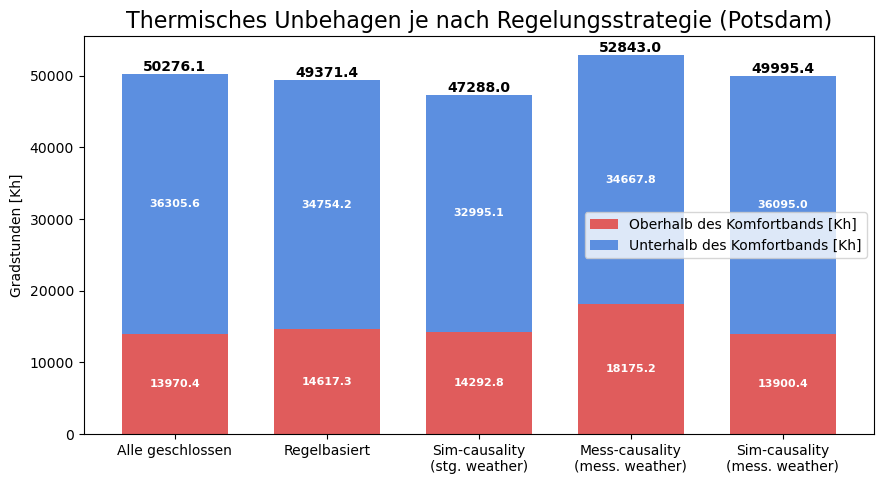

In [12]:
# nur der Median run je Strategie (nach Komfortstunden, wie im Scatter-Plot)
median_data = median_run_data(data)
overheating_kh = median_data.groupby("source")["overheating"].sum() / 6
undercooling_kh = median_data.groupby("source")["undercooling"].sum() / 6

summary = pd.DataFrame({
    "Oberhalb des Komfortbands [Kh]": overheating_kh,
    "Unterhalb des Komfortbands [Kh]": undercooling_kh,
}).reindex(SOURCES_TO_COMPARE).dropna()
summary.index = [name_to_short_label.get(source, source) for source in summary.index]

# plot
ax = summary.plot(kind="bar", stacked=True, figsize=(9, 5), color=["#e05c5c", "#5c8fe0"], width=0.7)

# annotate each segment
for bar_group in ax.containers:
    ax.bar_label(bar_group, fmt="%.1f", label_type="center", fontsize=8, color="white", fontweight="bold")

# annotate total on top
for i, total in enumerate(summary.sum(axis=1)):
    ax.text(i, total + 0.5, f"{total:.1f}", ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

plt.ylabel("Gradstunden [Kh]")
plt.xlabel("")
plt.title(f"Thermisches Unbehagen je nach Regelungsstrategie ({name_to_short_label.get(TEST_PHASE, TEST_PHASE)})")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

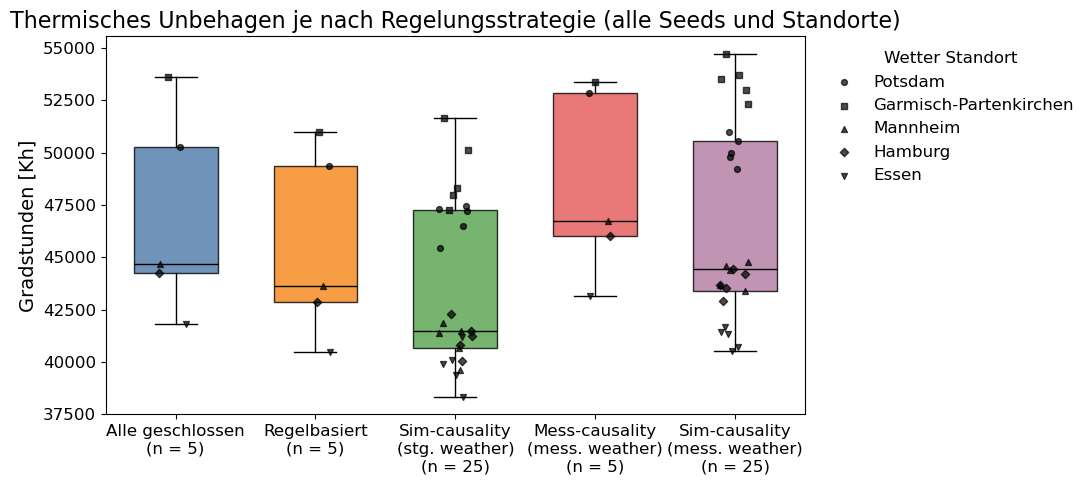

In [13]:
# one total discomfort value (Kh) per run (source, seed, test_phase)
discomfort_per_run = (
    all_data.assign(total_discomfort=all_data["overheating"] + all_data["undercooling"])
    .groupby(["source", "seed", "test_phase"], dropna=False)["total_discomfort"].sum() / 6
).rename("Discomfort Kh").reset_index()

# keep order of SOURCES_TO_COMPARE and drop sources without data
sources = [s for s in SOURCES_TO_COMPARE if s in discomfort_per_run["source"].unique()]
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#B279A2", "#72B7B2", "#FF9DA6"]

# alle Läufe (Seeds × Standorte) je Strategie
box_data = [discomfort_per_run.loc[discomfort_per_run["source"] == s, "Discomfort Kh"].values for s in sources]
labels = [f"{name_to_short_label.get(s, s)}\n(n = {len(v)})" for s, v in zip(sources, box_data)]

# plot
fig, ax = plt.subplots(figsize=(11, 5))
bp = ax.boxplot(box_data, patch_artist=True, widths=0.6, tick_labels=labels, whis=(0, 100))

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
for median in bp["medians"]:
    median.set_color("black")

# overlay the individual runs, eine Markerform je Standort (leicht horizontal verteilt)
PHASE_MARKERS = dict(zip(ALL_TEST_PHASES, ["o", "s", "^", "D", "v", "P", "X"]))
rng = np.random.default_rng(0)
for i, source in enumerate(sources, start=1):
    runs = discomfort_per_run[discomfort_per_run["source"] == source]
    for phase, marker in PHASE_MARKERS.items():
        values = runs.loc[runs["test_phase"] == phase, "Discomfort Kh"].values
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(values)), values, marker=marker,
                   color="black", s=18, alpha=0.7, zorder=3,
                   label=name_to_short_label.get(phase, phase) if i == 1 else None)
ax.legend(title="Wetter Standort", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)

ax.set_ylabel("Gradstunden [Kh]")
ax.set_xlabel("")
ax.set_title("Thermisches Unbehagen je nach Regelungsstrategie (alle Seeds und Standorte)")
plt.tight_layout()
plt.show()

# Ergebnisse: Seed-Studie DQN-sim vs. DQN-real

Alle Werte aus dem Zwilling (Jahressimulation, 5 Teststandorte), bewertet mit dem adaptiven Komfortband nach EN 16798-1.

* **Regelbasiert**: Referenz (Band 20–22 °C)
* **DQN-sim**: im Zwilling mit Messwetter trainiert, 5 Seeds
* **DQN-real**: an Feldmessdaten trainiert (1 Lauf)

Beide DQN: gleiche Belohnung, gleiche Eingänge, gleicher Trainingszeitraum (7.9.–16.11.2026).
Angegeben ist jeweils die Abweichung zum regelbasierten Regler **am selben Standort** in %.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS = Path(r"C:\Users\lkclu\Documents\GitHub\DTFS\results\control")
CITIES = {"essen": "Essen", "garmisch": "Garmisch-P.", "hamburg": "Hamburg", "mannheim": "Mannheim", "potsdam": "Potsdam"}
SEEDS = [1, 2, 3, 4, 5]
SIM_PREFIX = "drl_ambient_adjusted_weather_like_measured_seed"
RUNS = {"hard_coded_control": ("Regelbasiert", None),
        "drl_ambient_adjusted_measured": ("DQN-real", None),
        **{f"{SIM_PREFIX}{s}": ("DQN-sim", s) for s in SEEDS}}
COLORS = {"Regelbasiert": "#7f7f7f", "DQN-sim": "#2a78d6", "DQN-real": "#eb6834"}
TRAIN_START_H, TRAIN_END_H = 5994, 7670          # 7.9.-16.11. (Stunden ab 1.1.)
PERIODS = {
    "Ganzes Jahr": lambda m, t: np.ones_like(t, dtype=bool),
    "Trainingszeitraum\n(7.9.–16.11.)": lambda m, t: (t >= TRAIN_START_H) & (t < TRAIN_END_H),
    "Sommer\n(Jun–Aug)": lambda m, t: np.isin(m, [6, 7, 8]),
    "Winter\n(Dez–Feb)": lambda m, t: np.isin(m, [12, 1, 2]),
}
STEP_H = 1 / 6

def comfort_band(t_amb):
    lower = np.where(t_amb < 16, 20.0, np.where(t_amb < 32, 16 + 0.25 * t_amb, 24.0))
    return lower, lower + 4

def load_run(path):
    with open(path, encoding="utf-8") as f:
        rec = [json.loads(line) for line in f if line.strip()]
    return (np.array([r["misc"]["current_time"] for r in rec]),
            np.array([r["state"]["dry_bulb_temperature"] for r in rec]),
            np.array([r["state"]["operative_temperature"] for r in rec]))

rows, missing = [], []
for city, city_label in CITIES.items():
    for run, (controller, seed) in RUNS.items():
        files = list((RESULTS / f"simulation_full_year_{city}" / run).glob("*.jsonl"))
        if not files:
            missing.append(f"{city}/{run}")
            continue
        t, t_amb, t_op = load_run(files[0])
        lo, hi = comfort_band(t_amb)
        outside = (t_op < lo) | (t_op > hi)
        dev = np.clip(lo - t_op, 0, None) + np.clip(t_op - hi, 0, None)
        month = (t // (8760 / 12)).astype(int) + 1
        for period, sel in PERIODS.items():
            m = sel(month, t)
            rows.append(dict(city=city_label, controller=controller, seed=seed, period=period,
                             hours=outside[m].sum() * STEP_H, kh=dev[m].sum() * STEP_H))
kpi = pd.DataFrame(rows)
kpi["seed"] = kpi["seed"].astype("Int64")
if missing:
    print("Fehlende Ergebnisse (werden ausgelassen):", missing)

# Abweichung zum regelbasierten Regler am selben Standort und im selben Zeitraum
ref = kpi[kpi.controller == "Regelbasiert"].set_index(["city", "period"])[["hours", "kh"]]
kpi = kpi.join(ref, on=["city", "period"], rsuffix="_rb")
kpi["d_hours"] = (kpi.hours / kpi.hours_rb - 1) * 100
kpi["d_kh"] = (kpi.kh / kpi.kh_rb - 1) * 100
kpi.head()

,city,controller,seed,period,hours,kh,hours_rb,kh_rb,d_hours,d_kh
0,Essen,Regelbasiert,<NA>,Ganzes Jahr,6606.833333,34510.273334,6606.833333,34510.273334,0.000000,0.000000
1,Essen,Regelbasiert,<NA>,Trainingszeitraum\n(7.9.–16.11.),1062.000000,3644.126860,1062.000000,3644.126860,0.000000,0.000000
2,Essen,Regelbasiert,<NA>,Sommer\n(Jun–Aug),1259.833333,3592.058130,1259.833333,3592.058130,0.000000,0.000000
3,Essen,Regelbasiert,<NA>,Winter\n(Dez–Feb),2182.333333,17999.605676,2182.333333,17999.605676,0.000000,0.000000
4,Essen,DQN-real,<NA>,Ganzes Jahr,7006.666667,35589.469400,6606.833333,34510.273334,6.051815,3.127173


In [15]:
# --- Übersichtstabelle: Median [Min, Max] über Standorte (und Seeds bei DQN-sim) ---
def fmt(s):
    return f"{s.median():+.1f} % [{s.min():+.1f}, {s.max():+.1f}]"

summary = []
for period in PERIODS:
    sub = kpi[kpi.period == period]
    rb = sub[sub.controller == "Regelbasiert"]
    for controller in ["DQN-sim", "DQN-real"]:
        c = sub[sub.controller == controller]
        summary.append({
            "Zeitraum": period.replace("\n", " "),
            "Regler": controller,
            "n (Läufe × Standorte)": len(c),
            "Stunden außerhalb vs. regelbasiert": fmt(c.d_hours),
            "Kh vs. regelbasiert": fmt(c.d_kh),
            "Regelbasiert: Stunden (Median)": f"{rb.hours.median():.0f} h",
            "Regelbasiert: Kh (Median)": f"{rb.kh.median():.0f} Kh",
        })
summary = pd.DataFrame(summary).set_index(["Zeitraum", "Regler"])
summary

n (Läufe × Standorte)  \
Zeitraum                        Regler                            
Ganzes Jahr                     DQN-sim                      25   
                                DQN-real                      5   
Trainingszeitraum (7.9.–16.11.) DQN-sim                      25   
                                DQN-real                      5   
Sommer (Jun–Aug)                DQN-sim                      25   
                                DQN-real                      5   
Winter (Dez–Feb)                DQN-sim                      25   
                                DQN-real                      5   

                                         Stunden außerhalb vs. regelbasiert  \
Zeitraum                        Regler                                        
Ganzes Jahr                     DQN-sim                 +3.2 % [-2.1, +5.9]   
                                DQN-real                +6.0 % [+2.4, +6.8]   
Trainingszeitraum (7.9.–16.11.) DQN-sim                +1.2 % [-9.8, +13.2]   
                                DQN-real                -1.8 % [-4.5, +6.1]   
Sommer (Jun–Aug)                DQN-sim                 +1.9 % [-3.5, +9.9]   
                                DQN-real             +21.5 % [+16.7, +27.3]   
Winter (Dez–Feb)                DQN-sim                 +0.2 % [-0.5, +0.7]   
                                DQN-real                +0.0 % [-0.2, +0.1]   

                                             Kh vs. regelbasiert  \
Zeitraum                        Regler                             
Ganzes Jahr                     DQN-sim      +2.7 % [-0.4, +7.8]   
                                DQN-real     +4.1 % [+2.6, +5.0]   
Trainingszeitraum (7.9.–16.11.) DQN-sim      +1.9 % [-6.5, +8.2]   
                                DQN-real     +2.1 % [-0.4, +8.9]   
Sommer (Jun–Aug)                DQN-sim     -5.5 % [-14.5, -0.1]   
                                DQN-real  +20.5 % [+13.9, +21.7]   
Winter (Dez–Feb)                DQN-sim      +3.9 % [+1.6, +8.7]   
                                DQN-real     +0.5 % [+0.4, +0.9]   

                                         Regelbasiert: Stunden (Median)  \
Zeitraum                        Regler                                    
Ganzes Jahr                     DQN-sim                          6813 h   
                                DQN-real                         6813 h   
Trainingszeitraum (7.9.–16.11.) DQN-sim                          1147 h   
                                DQN-real                         1147 h   
Sommer (Jun–Aug)                DQN-sim                          1314 h   
                                DQN-real                         1314 h   
Winter (Dez–Feb)                DQN-sim                          2176 h   
                                DQN-real                         2176 h   

                                         Regelbasiert: Kh (Median)  
Zeitraum                        Regler                              
Ganzes Jahr                     DQN-sim                   37501 Kh  
                                DQN-real                  37501 Kh  
Trainingszeitraum (7.9.–16.11.) DQN-sim                    3899 Kh  
                                DQN-real                   3899 Kh  
Sommer (Jun–Aug)                DQN-sim                    3677 Kh  
                                DQN-real                   3677 Kh  
Winter (Dez–Feb)                DQN-sim                   20367 Kh  
                                DQN-real                  20367 Kh

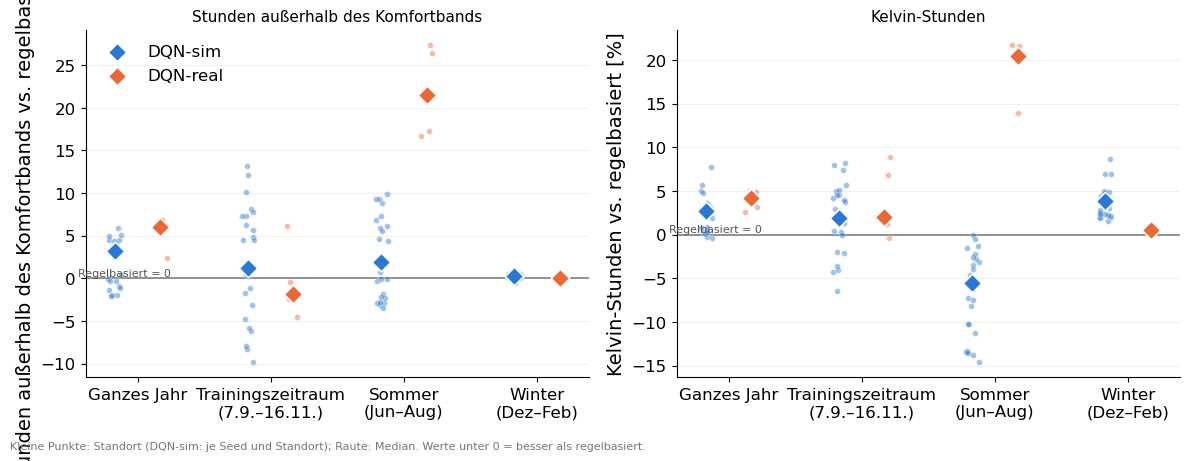

In [16]:
# --- Abbildung 1: Abweichung zum regelbasierten Regler je Zeitraum ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True)
periods = list(PERIODS)
offsets = {"DQN-sim": -0.17, "DQN-real": 0.17}
rng = np.random.default_rng(0)
for ax, (col, label) in zip(axes, [("d_hours", "Stunden außerhalb des Komfortbands"), ("d_kh", "Kelvin-Stunden")]):
    ax.axhline(0, color="#7f7f7f", lw=1.2, zorder=1)
    ax.text(-0.45, 0, "Regelbasiert = 0", va="bottom", ha="left", fontsize=8, color="#55554f")
    for i, period in enumerate(periods):
        for controller, off in offsets.items():
            vals = kpi[(kpi.period == period) & (kpi.controller == controller)][col]
            x = i + off + rng.uniform(-0.05, 0.05, len(vals))
            ax.scatter(x, vals, s=18, color=COLORS[controller], alpha=0.45, edgecolor="white", linewidth=0.5, zorder=2)
            ax.scatter(i + off, vals.median(), s=90, marker="D", color=COLORS[controller], edgecolor="white", linewidth=1.2, zorder=3,
                       label=controller if i == 0 else None)
    ax.set_xticks(range(len(periods)), periods)
    ax.set_ylabel(f"{label} vs. regelbasiert [%]")
    ax.set_title(label, fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#ececE8", lw=0.6); ax.set_axisbelow(True)
axes[0].legend(frameon=False, loc="upper left")
fig.text(0.01, 0.005, "Kleine Punkte: Standort (DQN-sim: je Seed und Standort); Raute: Median. Werte unter 0 = besser als regelbasiert.",
         fontsize=8, color="#77776f")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

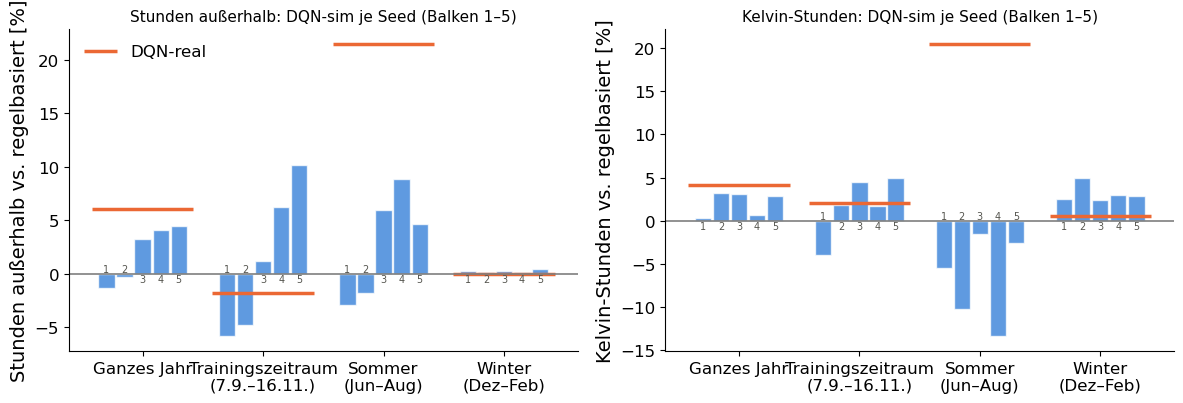

DQN-sim je Seed, Median über die Standorte [% vs. regelbasiert]:


d_hours                                                     \
period Ganzes Jahr Sommer\n(Jun–Aug) Trainingszeitraum\n(7.9.–16.11.)   
seed                                                                    
1             -1.3              -2.9                             -5.8   
2             -0.3              -1.8                             -4.8   
3              3.2               5.9                              1.2   
4              4.1               8.9                              6.2   
5              4.5               4.7                             10.2   

                                d_kh                    \
period Winter\n(Dez–Feb) Ganzes Jahr Sommer\n(Jun–Aug)   
seed                                                     
1                    0.3         0.3              -5.5   
2                    0.2         3.2             -10.3   
3                    0.2         3.2              -1.5   
4                    0.1         0.7             -13.4   
5                    0.4         2.8              -2.6   

                                                           
period Trainingszeitraum\n(7.9.–16.11.) Winter\n(Dez–Feb)  
seed                                                       
1                                  -4.0               2.5  
2                                   1.9               4.9  
3                                   4.5               2.4  
4                                   1.7               3.0  
5                                   5.0               2.9

In [17]:
# --- Abbildung 2: Streuung über die Seeds (Median über die Standorte) ---
per_seed = (kpi[kpi.controller == "DQN-sim"].groupby(["period", "seed"])[["d_hours", "d_kh"]].median().reset_index())
real = kpi[kpi.controller == "DQN-real"].groupby("period")[["d_hours", "d_kh"]].median()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
w = 0.15
for ax, (col, label) in zip(axes, [("d_hours", "Stunden außerhalb"), ("d_kh", "Kelvin-Stunden")]):
    for i, period in enumerate(periods):
        sub = per_seed[per_seed.period == period].sort_values("seed")
        xs = i + (np.arange(len(sub)) - (len(sub) - 1) / 2) * w
        ax.bar(xs, sub[col], width=w * 0.9, color=COLORS["DQN-sim"], alpha=0.75, edgecolor="white", linewidth=1)
        for x, s, v in zip(xs, sub.seed, sub[col]):
            ax.text(x, 0, f"{int(s)}", ha="center", va="top" if v >= 0 else "bottom", fontsize=7, color="#55554f")
        ax.hlines(real.loc[period, col], i - 0.42, i + 0.42, color=COLORS["DQN-real"], lw=2.5,
                  label="DQN-real" if i == 0 else None)
    ax.axhline(0, color="#7f7f7f", lw=1.2)
    ax.set_xticks(range(len(periods)), periods)
    ax.set_ylabel(f"{label} vs. regelbasiert [%]")
    ax.set_title(f"{label}: DQN-sim je Seed (Balken 1–5)", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

print("DQN-sim je Seed, Median über die Standorte [% vs. regelbasiert]:")
per_seed.pivot(index="seed", columns="period", values=["d_hours", "d_kh"]).round(1)

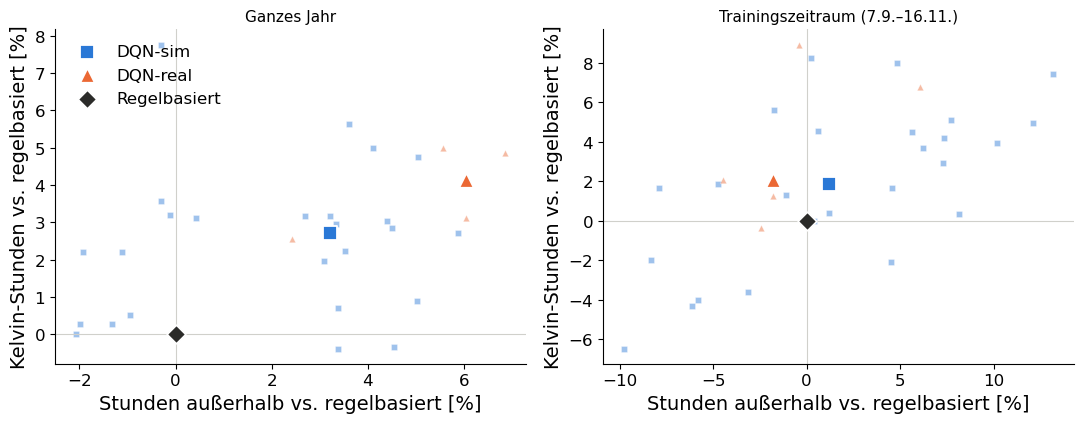

In [18]:
# --- Abbildung 3: Häufigkeit vs. Schwere (ganzes Jahr und Trainingszeitraum) ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, period in zip(axes, [periods[0], periods[1]]):
    sub = kpi[kpi.period == period]
    ax.axhline(0, color="#d0d0cb", lw=0.8); ax.axvline(0, color="#d0d0cb", lw=0.8)
    for controller, marker in [("DQN-sim", "s"), ("DQN-real", "^")]:
        c = sub[sub.controller == controller]
        ax.scatter(c.d_hours, c.d_kh, s=22, marker=marker, color=COLORS[controller], alpha=0.45, edgecolor="white", linewidth=0.5)
        ax.scatter(c.d_hours.median(), c.d_kh.median(), s=110, marker=marker, color=COLORS[controller],
                   edgecolor="white", linewidth=1.3, label=controller, zorder=3)
    ax.scatter(0, 0, s=90, marker="D", color="#2b2b29", edgecolor="white", linewidth=1.2, label="Regelbasiert", zorder=3)
    ax.set_title(period.replace("\n", " "), fontsize=11)
    ax.set_xlabel("Stunden außerhalb vs. regelbasiert [%]")
    ax.set_ylabel("Kelvin-Stunden vs. regelbasiert [%]")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

# Warum DQN-sim mehr Kelvin-Stunden hat

Vergleich von **DQN-sim** (im Zwilling trainiert, Messwetter), **DQN-real** (an Feldmessdaten trainiert) und dem regelbasierten Regler.
Beide Agenten haben dieselbe Belohnung, dieselben Eingänge und denselben Trainingszeitraum (7.9.–16.11.2026); sie unterscheiden sich nur in der Herkunft der Trainingsdaten.

1. Kh aufgeteilt in *unter* / *über* dem Komfortband → die zusätzlichen Kh von DQN-sim sind Unterkühlung.
2. Aktionswahl, wenn es kalt ist und die Zelle schon unter dem Band liegt → DQN-sim öffnet alle Klappen.
3. Anteil „alle offen“ je Monat → das Verhalten zieht sich durch die kalte Jahreszeit.
4. Trainingsdaten: Belohnung je Aktion bei Kälte → im Zwilling ist „alle offen“ die am wenigsten bestrafte Aktion, in der Realität die am stärksten bestrafte.
5. Trainingsdaten: nächtliche Abkühlrate je Aktion → im Zwilling kühlt „alle offen“ am stärksten ab (≈ 2,8× so schnell wie geschlossen, real ≈ 2×), die Zelle kühlt auch geschlossen etwa doppelt so schnell ab wie gemessen.

Hinweis zu 4. und 5.: Die Mittelwerte sind beschreibend. Die Agenten haben die Aktionen in unterschiedlichen Situationen gewählt (z. B. Tag/Nacht), und „alle offen“ kommt bei Kälte in den Felddaten nur selten vor (Anzahl wird ausgegeben). Dass „alle offen“ im Zwilling stark kühlt, aber kaum bestraft wird, deutet auch auf die kausalitätsgewichtete Belohnung hin: Folgt T_op beim Öffnen der Außentemperatur, wird die Strafe um bis zu 80 % abgeschwächt.

In [25]:
import sys
import numpy as np
import matplotlib.pyplot as plt

REPO = Path(r"C:\Users\lkclu\Documents\GitHub\DTFS")
TIMESTEP_H = 1 / 6  # 10-min time steps

# Name des sim-trainierten Agenten (mit Messwetter) - hier anpassen, wenn ein neuer Lauf unter anderem Namen gespeichert wird
SIM_SOURCE = "drl_ambient_adjusted_weather_like_measured_seed3"

KH_SOURCES = ["hard_coded_control", SIM_SOURCE, "drl_ambient_adjusted_measured"]
KH_LABELS = {
    "hard_coded_control": "Regelbasiert",
    SIM_SOURCE: "DQN-sim\n(Zwilling, Messwetter)",
    "drl_ambient_adjusted_measured": "DQN-real\n(Feldmessdaten)",
}
KH_COLORS = {"hard_coded_control": "#7f7f7f",
             SIM_SOURCE: "#2a78d6",
             "drl_ambient_adjusted_measured": "#eb6834"}
ACTION_NAMES = {0: "alle geschlossen", 1: "innen offen", -1: "außen offen", 2: "alle offen"}
ACTION_ORDER = [0, 1, -1, 2]
ACTION_COLORS = {0: "#4C72B0", 1: "#DD8452", -1: "#C44E52", 2: "#55A868"}

# "kalt und schon unter dem Komfortband": Außenluft < 12 °C und T_op unter der unteren Bandgrenze
COLD_T_AMB = 12.0

missing = [s for s in KH_SOURCES if s not in set(all_data["source"])]
if missing:
    raise ValueError(f"Nicht in all_data geladen: {missing} - bitte in SOURCES_TO_COMPARE (Zelle 2) aufnehmen.")

kh_data = all_data[all_data["source"].isin(KH_SOURCES)].copy()
kh_data["cold_below"] = (kh_data["dry_bulb_temperature"] < COLD_T_AMB) & (kh_data["operative_temperature"] < kh_data["t_low"])
kh_data["month"] = (kh_data["current_time"] // (8760 / 12)).astype(int) + 1

ValueError: Nicht in all_data geladen: ['drl_ambient_adjusted_weather_like_measured_seed3'] - bitte in SOURCES_TO_COMPARE (Zelle 2) aufnehmen.

Abweichung zu regelbasiert [%]:
                                                  undercooling  overheating
source                                                                     
hard_coded_control                                         0.0          0.0
drl_ambient_adjusted_weather_like_measured_seed3           4.5          1.5
drl_ambient_adjusted_measured                              0.4         27.6


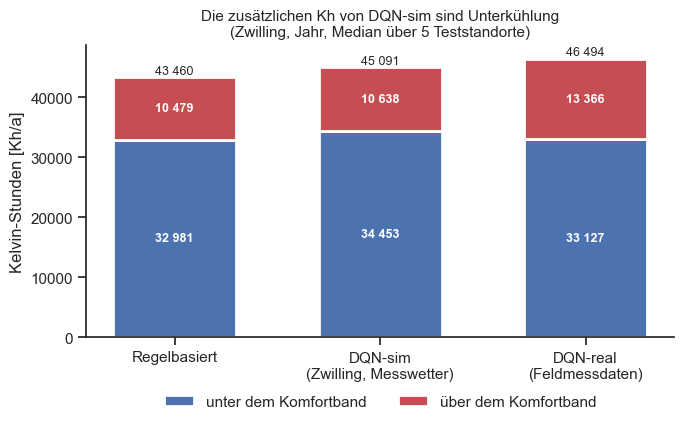

In [ ]:
# --- 1. Kelvin-Stunden unter / über dem Komfortband (Median über die Teststandorte) ---
kh_split = (
    kh_data.groupby(["source", "test_phase"])[["undercooling", "overheating"]].sum().mul(TIMESTEP_H)
    .groupby("source").median().reindex(KH_SOURCES)
)
rb = kh_split.loc["hard_coded_control"]
print("Abweichung zu regelbasiert [%]:")
print(((kh_split / rb - 1) * 100).round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(KH_SOURCES))
ax.bar(x, kh_split["undercooling"], width=0.6, color="#4C72B0", label="unter dem Komfortband", edgecolor="white", linewidth=2)
ax.bar(x, kh_split["overheating"], width=0.6, bottom=kh_split["undercooling"], color="#C44E52",
       label="über dem Komfortband", edgecolor="white", linewidth=2)
for i, src in enumerate(KH_SOURCES):
    u, o = kh_split.loc[src, "undercooling"], kh_split.loc[src, "overheating"]
    ax.text(i, u / 2, f"{u:,.0f}".replace(",", " "), ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    ax.text(i, u + o / 2, f"{o:,.0f}".replace(",", " "), ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    ax.text(i, u + o, f"{u + o:,.0f}".replace(",", " "), ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, [KH_LABELS[s] for s in KH_SOURCES])
ax.set_ylabel("Kelvin-Stunden [Kh/a]")
ax.set_title("Die zusätzlichen Kh von DQN-sim sind Unterkühlung\n(Zwilling, Jahr, Median über 5 Teststandorte)", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.tight_layout()
plt.show()

Anteil der Aktionen bei T_amb < 12.0 °C und T_op < unterer Bandgrenze (alle Standorte, ganzes Jahr):
control                                           alle geschlossen  \
source                                                               
hard_coded_control                                            69.0   
drl_ambient_adjusted_weather_like_measured_seed3              68.0   
drl_ambient_adjusted_measured                                 62.0   

control                                           innen offen  außen offen  \
source                                                                       
hard_coded_control                                       31.0          0.0   
drl_ambient_adjusted_weather_like_measured_seed3         24.0          4.0   
drl_ambient_adjusted_measured                            30.0          8.0   

control                                           alle offen  
source                                                        
hard_coded_control             

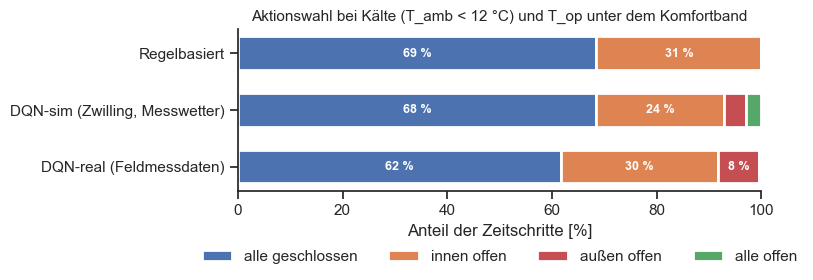

In [ ]:
# --- 2. Aktionswahl, wenn es kalt ist und die Zelle schon unter dem Band liegt ---
cold = kh_data[kh_data["cold_below"]]
shares = (cold.groupby("source")["control"].value_counts(normalize=True)
          .unstack(fill_value=0).reindex(index=KH_SOURCES, columns=ACTION_ORDER, fill_value=0))
print(f"Anteil der Aktionen bei T_amb < {COLD_T_AMB} °C und T_op < unterer Bandgrenze (alle Standorte, ganzes Jahr):")
print((shares.rename(columns=ACTION_NAMES) * 100).round(0))

fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(KH_SOURCES))[::-1]
left = np.zeros(len(KH_SOURCES))
for a in ACTION_ORDER:
    vals = shares[a].values * 100
    ax.barh(y, vals, left=left, color=ACTION_COLORS[a], label=ACTION_NAMES[a], height=0.6, edgecolor="white", linewidth=2)
    for yi, l, v in zip(y, left, vals):
        if v >= 6:
            ax.text(l + v / 2, yi, f"{v:.0f} %", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += vals
ax.set_yticks(y, [KH_LABELS[s].replace("\n", " ") for s in KH_SOURCES])
ax.set_xlim(0, 100)
ax.set_xlabel("Anteil der Zeitschritte [%]")
ax.set_title(f"Aktionswahl bei Kälte (T_amb < {COLD_T_AMB:.0f} °C) und T_op unter dem Komfortband", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.28))
plt.tight_layout()
plt.show()

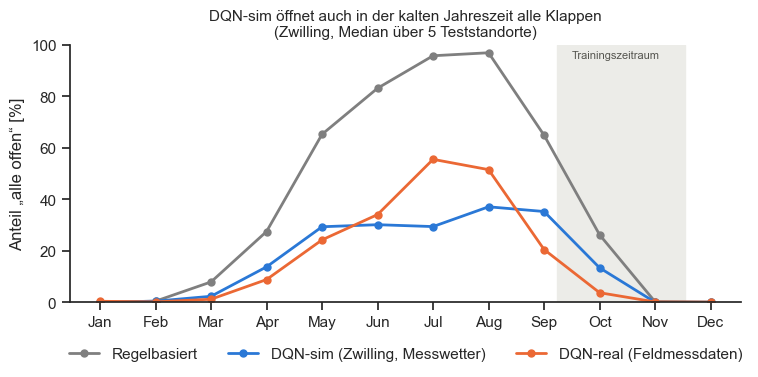

In [ ]:
# --- 3. Anteil "alle offen" je Monat (Median über die Teststandorte) ---
monthly_open = (
    kh_data.assign(all_open=kh_data["control"] == CONTROL_ACTIONS["all_open"])
    .groupby(["source", "test_phase", "month"])["all_open"].mean()
    .groupby(["source", "month"]).median().unstack("source")[KH_SOURCES] * 100
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.axvspan(9 + 7 / 30, 11 + 16 / 30, color="#ececE8", zorder=0)
ax.text(10.3, 98, "Trainingszeitraum", ha="center", va="top", fontsize=8, color="#55554f")
for src in KH_SOURCES:
    ax.plot(monthly_open.index, monthly_open[src], marker="o", lw=2, ms=5, color=KH_COLORS[src],
            label=KH_LABELS[src].replace("\n", " "))
ax.set_xticks(range(1, 13), [pd.Timestamp(2024, m, 1).strftime("%b") for m in range(1, 13)])
ax.set_ylim(0, 100)
ax.set_ylabel("Anteil „alle offen“ [%]")
ax.set_title("DQN-sim öffnet auch in der kalten Jahreszeit alle Klappen\n(Zwilling, Median über 5 Teststandorte)", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.tight_layout()
plt.show()

In [ ]:
# --- Trainingsdaten beider Agenten laden und die Belohnung mit derselben Funktion wie im Training nachrechnen ---
sys.path.append(str(REPO))
from connect_protocols.simulation_env import SimulationEnv

reward_env = SimulationEnv(reward="ambient_adjusted")
TRAINING_SOURCES = {
    SIM_SOURCE: "Zwilling (DQN-sim)",
    "drl_ambient_adjusted_measured": "Realität (DQN-real)",
}

transition_frames = []
for src, label in TRAINING_SOURCES.items():
    path = REPO / "results" / "models" / "online" / src / "online.jsonl"
    with open(path, encoding="utf-8") as f:
        tr = pd.json_normalize([json.loads(line) for line in f if line.strip()])
    tr.columns = [c.split(".")[-1] for c in tr.columns]
    tr = tr.reset_index(drop=True)  # chronological order as logged
    nxt = tr.shift(-1)
    step_min = (nxt["current_time"] - tr["current_time"]) * 60
    valid = step_min.between(8, 12)  # only regular 10-min steps (drops data gaps and the DST jump)
    states = tr[["dry_bulb_temperature", "total_horizontal_radiation", "operative_temperature"]].to_dict("records")
    rewards = [reward_env._reward(states[i], states[i + 1]) if (i + 1 < len(states) and valid.iloc[i]) else np.nan
               for i in range(len(states))]
    tr["reward"] = rewards
    tr["dT_op"] = nxt["operative_temperature"] - tr["operative_temperature"]
    tr["data"] = label
    transition_frames.append(tr[valid])

transitions = pd.concat(transition_frames, ignore_index=True)
transitions["cold_below"] = (transitions["dry_bulb_temperature"] < COLD_T_AMB) & (transitions["operative_temperature"] < 20)
transitions["night_warm"] = (transitions["total_horizontal_radiation"] < 10) & \
                            (transitions["operative_temperature"] - transitions["dry_bulb_temperature"] > 5)
transitions.groupby("data").size()

data
Realität (DQN-real)     8270
Zwilling (DQN-sim)     10055
dtype: int64

Mittlere Belohnung je Schritt bei Kälte und T_op < 20 °C:
data     Realität (DQN-real)  Zwilling (DQN-sim)
control                                         
-1                   -0.0346             -0.0400
 0                   -0.0140              0.0043
 1                    0.0097             -0.0142
 2                   -0.0422             -0.1060
Anzahl Schritte:
data     Realität (DQN-real)  Zwilling (DQN-sim)
control                                         
-1                       412                 100
 0                      2381                1256
 1                       131                3095
 2                        96                  58
Mittlere Änderung T_op je 10 min nachts (Zelle > 5 K wärmer als außen):
data     Realität (DQN-real)  Zwilling (DQN-sim)
control                                         
-1                    -0.036              -0.123
 0                    -0.021              -0.065
 1                    -0.062              -0.035
 2                  

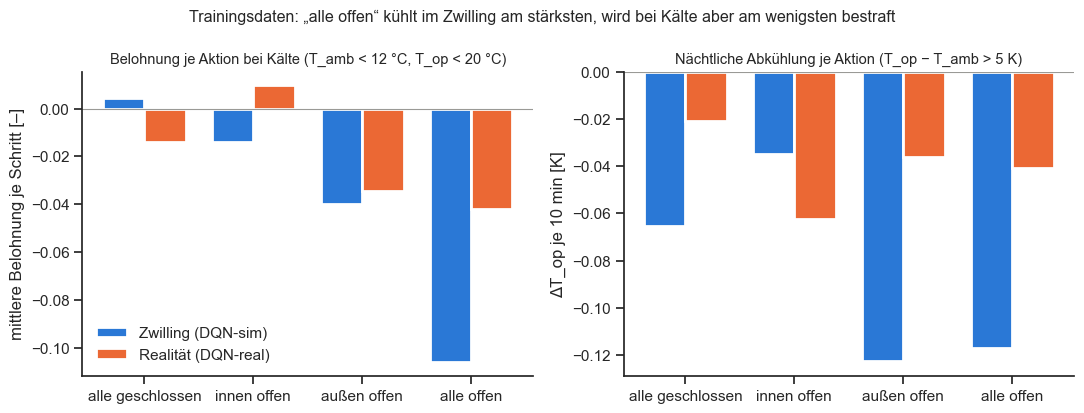

In [ ]:
# --- 4./5. Belohnung und Abkühlrate je Aktion in den Trainingsdaten ---
def grouped_bars(ax, table, ylabel, title):
    data_labels = list(TRAINING_SOURCES.values())
    colors = {data_labels[0]: KH_COLORS[SIM_SOURCE],
              data_labels[1]: KH_COLORS["drl_ambient_adjusted_measured"]}
    x = np.arange(len(ACTION_ORDER))
    w = 0.38
    for k, lab in enumerate(data_labels):
        vals = table.reindex(index=ACTION_ORDER)[lab].values
        ax.bar(x + (k - 0.5) * w, vals, width=w, color=colors[lab], label=lab, edgecolor="white", linewidth=2)
    ax.axhline(0, color="#9a9a96", lw=0.8)
    ax.set_xticks(x, [ACTION_NAMES[a] for a in ACTION_ORDER])
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10.5)
    ax.spines[["top", "right"]].set_visible(False)

reward_by_action = transitions[transitions["cold_below"]].pivot_table(
    index="control", columns="data", values="reward", aggfunc="mean")
cooling_by_action = transitions[transitions["night_warm"]].pivot_table(
    index="control", columns="data", values="dT_op", aggfunc="mean")
counts = transitions[transitions["cold_below"]].pivot_table(index="control", columns="data", values="reward", aggfunc="size")
print("Mittlere Belohnung je Schritt bei Kälte und T_op < 20 °C:"); print(reward_by_action.round(4))
print("Anzahl Schritte:"); print(counts)
print("Mittlere Änderung T_op je 10 min nachts (Zelle > 5 K wärmer als außen):"); print(cooling_by_action.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
grouped_bars(axes[0], reward_by_action, "mittlere Belohnung je Schritt [–]",
             f"Belohnung je Aktion bei Kälte (T_amb < {COLD_T_AMB:.0f} °C, T_op < 20 °C)")
grouped_bars(axes[1], cooling_by_action, "ΔT_op je 10 min [K]",
             "Nächtliche Abkühlung je Aktion (T_op − T_amb > 5 K)")
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("Trainingsdaten: „alle offen“ kühlt im Zwilling am stärksten, wird bei Kälte aber am wenigsten bestraft", fontsize=11.5)
plt.tight_layout()
plt.show()

# Visualizaion learning

In [19]:
TRAINING_RESULTS_PATH = Path(fr"C:\Users\lkclu\Documents\GitHub\DTFS\results\models\online")

drl_models = {s for s in SOURCES_TO_COMPARE if s.startswith("drl_")}

training_frames = []
for experiment_path in TRAINING_RESULTS_PATH.iterdir():
    metrics_path = experiment_path / "training_metrics.jsonl"
    print(metrics_path)
    if not metrics_path.is_file() or experiment_path.name not in drl_models:
        continue
    
    metrics = pd.read_json(metrics_path, lines=True).dropna(subset=["reward"]).copy()
    metrics["cumulative_reward"] = metrics["reward"].cumsum()
    metrics["source"] = experiment_path.name.removeprefix("gym_")
    training_frames.append(metrics)

training_metrics = pd.concat(training_frames, ignore_index=True)

C:\Users\lkclu\Documents\GitHub\DTFS\results\models\online\drl_ambient_adjusted\training_metrics.jsonl
C:\Users\lkclu\Documents\GitHub\DTFS\results\models\online\drl_ambient_adjusted_measured\training_metrics.jsonl
C:\Users\lkclu\Documents\GitHub\DTFS\results\models\online\drl_ambient_adjusted_seed1\training_metrics.jsonl
C:\Users\lkclu\Documents\GitHub\DTFS\results\models\online\drl_ambient_adjusted_seed2\training_metrics.jsonl
C:\Users\lkclu\Documents\GitHub\DTFS\results\models\online\drl_ambient_adjusted_seed3\training_metrics.jsonl
C:\Users\lkclu\Documents\GitHub\DTFS\results\models\online\drl_ambient_adjusted_seed4\training_metrics.jsonl
C:\Users\lkclu\Documents\GitHub\DTFS\results\models\online\drl_ambient_adjusted_seed5\training_metrics.jsonl
C:\Users\lkclu\Documents\GitHub\DTFS\results\models\online\drl_ambient_adjusted_weather_like_measured_seed1\training_metrics.jsonl
C:\Users\lkclu\Documents\GitHub\DTFS\results\models\online\drl_ambient_adjusted_weather_like_measured_seed2\t

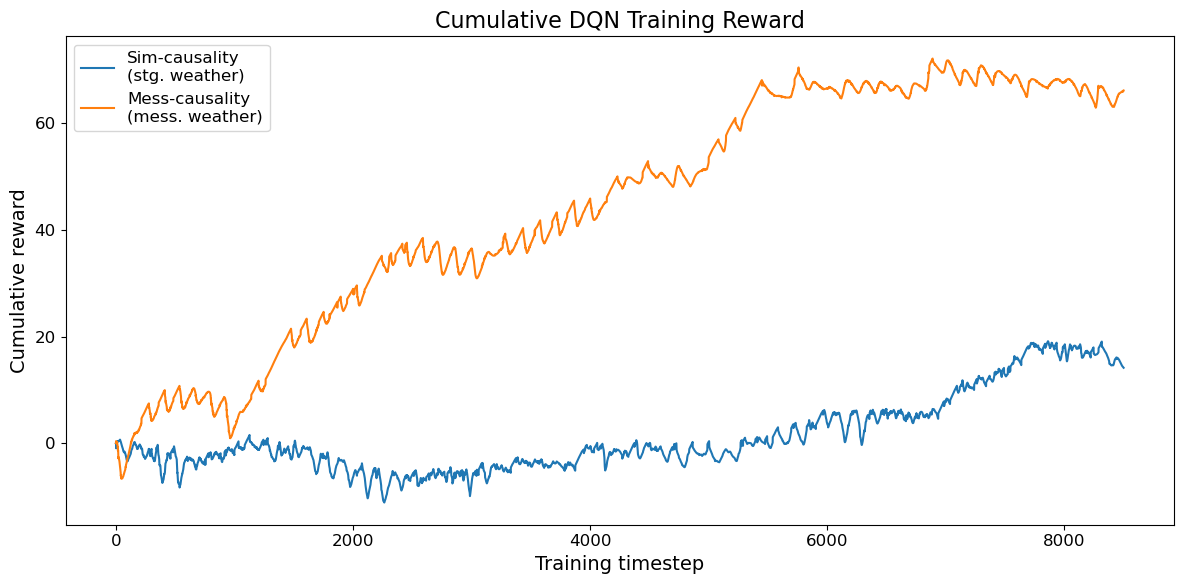

In [21]:
fig, ax = plt.subplots(figsize=(12, 6))
for source, subset in training_metrics.groupby("source"):
    ax.plot(
        subset["timesteps"],
        subset["cumulative_reward"],
        label=name_to_short_label.get(source, source),
    )

ax.set_xlabel("Training timestep")
ax.set_ylabel("Cumulative reward")
ax.set_title("Cumulative DQN Training Reward")
ax.legend()
plt.tight_layout()
plt.show()

In [22]:
import json
import pandas as pd
import seaborn as sns

training_frames = []
for experiment_path in TRAINING_RESULTS_PATH.iterdir():
    online_path = experiment_path / "online.jsonl"
    if not online_path.is_file() or experiment_path.name not in drl_models:
        continue

    with online_path.open() as f:
        records = [json.loads(line) for line in f if line.strip()]  # skips the empty last line

    online = pd.json_normalize(records)   # columns like "state.total_horizontal_radiation"
    online = online.rename(columns={
        "state.total_horizontal_radiation": "irradiation",
        "state.dry_bulb_temperature": "ambient_temp",
        "state.operative_temperature": "operative_temp",
        "misc.hour_of_day": "hour_of_day",
    })
    online["source"] = experiment_path.name.removeprefix("gym_")
    training_frames.append(online)

training_metrics = pd.concat(training_frames, ignore_index=True)

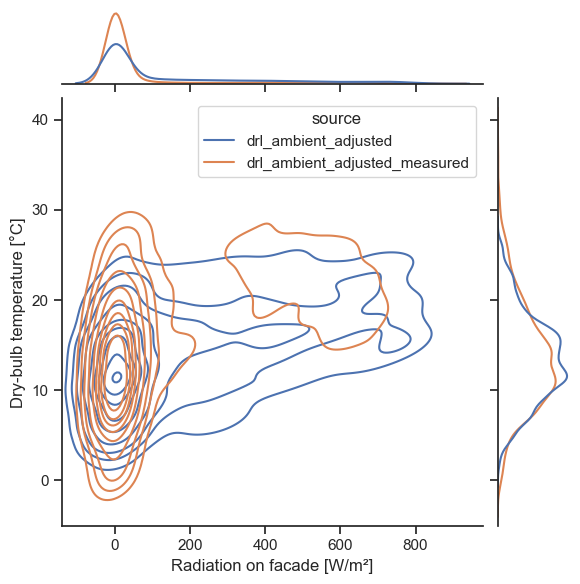

In [23]:
sns.set_theme(style="ticks")

g = sns.jointplot(
    data=training_metrics,
    x="irradiation", y="ambient_temp", hue="source",
    kind="kde",
)
g.set_axis_labels("Radiation on facade [W/m²]", "Dry-bulb temperature [°C]")

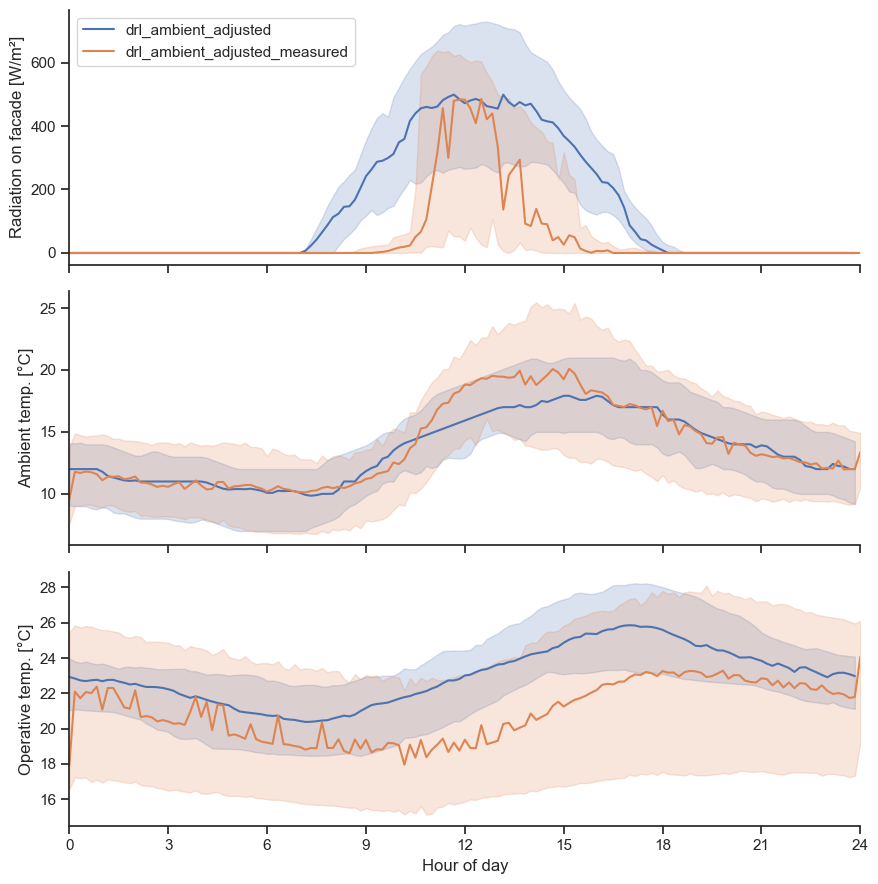

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="ticks")

df = training_metrics.copy()
# hour_of_day has float noise (20.66666666666697), so snap it to the 10-min grid
df["hour"] = (df["hour_of_day"] * 6).round() / 6

fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)

panels = [
    ("irradiation",    "Radiation on facade [W/m²]"),
    ("ambient_temp",   "Ambient temp. [°C]"),
    ("operative_temp", "Operative temp. [°C]"),
]

for ax, (col, label) in zip(axes, panels):
    sns.lineplot(
        data=df, x="hour", y=col, hue="source",
        estimator="median",
        errorbar=("pi", 50),   # band = 25th–75th percentile across days
        ax=ax, legend=(ax is axes[0]),
    )
    ax.set_ylabel(label)

axes[-1].set_xlabel("Hour of day")
axes[-1].set_xticks(range(0, 25, 3))
axes[-1].set_xlim(0, 24)
sns.move_legend(axes[0], "upper left", title=None)
sns.despine(fig)
fig.tight_layout()